# Exploração inicial dos dados e preparação de rotinas de processamento

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent  # if notebook is in notebooks/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd

from src.paths import PROC_DIR
from src.data import load_raw_wands, materialize_processed

### Inspecting data

In [4]:
products, queries, labels = load_raw_wands()

### Produtos

In [5]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42994 entries, 0 to 42993
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           42994 non-null  int64  
 1   product_name         42994 non-null  object 
 2   product_class        40142 non-null  object 
 3   category hierarchy   41438 non-null  object 
 4   product_description  36986 non-null  object 
 5   product_features     42994 non-null  object 
 6   rating_count         33542 non-null  float64
 7   average_rating       33542 non-null  float64
 8   review_count         33542 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 3.0+ MB


In [6]:
products.sample(5)

,product_id,product_name,product_class,category hierarchy,product_description,product_features,rating_count,average_rating,review_count
5525,5525,minatare tufted upholstered low profile storag...,Beds,Furniture / Bedroom Furniture / Beds & Headboa...,NaN,mattresssize : queen|color : beige|mattresssiz...,337.0,5.0,235.0
8343,8343,dalke mid-century 5 piece pub table set,Dining Table Sets,Furniture / Kitchen & Dining Furniture / Dinin...,this dalke mid-century 5 piece pub table set i...,seatingcapacity:4|tableshape : square|overallt...,10.0,4.5,9.0
10134,10134,lahara toilet paper holder,Toilet Paper Holders,Home Improvement / Bathroom Remodel & Bathroom...,NaN,overalldepth-fronttoback:3.7|overallwidth-side...,131.0,4.5,64.0
19244,19244,nove adjustable bar stool,Bar Stools,Furniture / Kitchen & Dining Furniture / Bar F...,NaN,seatdepth-fronttoback:19|basecolor : chrome|ov...,NaN,NaN,NaN
8100,8100,beaconsdale 60 '' double bathroom vanity base ...,Vanity Bases,Home Improvement / Bathroom Remodel & Bathroom...,build your bathroom from the ground up with th...,numberofdrawerhandles:6|drawerinteriordepth-fr...,44.0,4.5,37.0


### Queries

In [7]:
queries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   query_id     480 non-null    int64 
 1   query        480 non-null    object
 2   query_class  474 non-null    object
dtypes: int64(1), object(2)
memory usage: 11.4+ KB


In [8]:
queries.sample(5)

,query_id,query,query_class
180,181,e12/candelabra,Light Bulbs
269,273,stainless steel free standing shower caddy,Shower & Tub Accessories
160,161,accent chair recliner,Recliners
217,221,small space dining table and chairs sets,Dining Table Sets
171,172,picasso,Wall Art


### Labels

In [9]:
labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233448 entries, 0 to 233447
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          233448 non-null  int64 
 1   query_id    233448 non-null  int64 
 2   product_id  233448 non-null  int64 
 3   label       233448 non-null  object
dtypes: int64(3), object(1)
memory usage: 7.1+ MB


In [10]:
labels.sample(5)

,id,query_id,product_id,label
108067,108219,213,12434,Partial
38083,38162,349,2316,Partial
80030,80181,121,6157,Irrelevant
87254,87405,135,10373,Irrelevant
163212,163779,412,21175,Partial


### Limpeza dos dados

In [11]:
materialize_processed()

{'products_raw': 42994,
 'products_proc': 42994,
 'queries_raw': 480,
 'queries_proc': 480,
 'labels_raw': 233448,
 'labels_proc': 231873}

### EDA dados limpos

In [12]:
proc_dir = Path(PROC_DIR)

In [13]:
products_proc = pd.read_parquet(proc_dir / 'products.parquet')
queries_proc = pd.read_parquet(proc_dir / 'queries.parquet')
labels_proc = pd.read_parquet(proc_dir / 'labels.parquet')

In [14]:
products_proc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42994 entries, 0 to 42993
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           42994 non-null  int64  
 1   product_name         42994 non-null  object 
 2   product_class        42994 non-null  object 
 3   category_hierarchy   42994 non-null  object 
 4   product_description  42994 non-null  object 
 5   product_features     42994 non-null  object 
 6   rating_count         33542 non-null  float64
 7   average_rating       33542 non-null  float64
 8   review_count         33542 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 3.0+ MB


### Queries

In [15]:
queries_proc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   query_id     480 non-null    int64 
 1   query        480 non-null    object
 2   query_class  480 non-null    object
dtypes: int64(1), object(2)
memory usage: 11.4+ KB


In [17]:
queries_proc.nunique()

query_id       480
query          480
query_class    189
dtype: int64

In [19]:
queries_proc['query_class'].value_counts()

query_class
Wall Art                    20
Accent Chairs               16
Beds                        15
Area Rugs                   15
Coffee & Cocktail Tables    10
                            ..
Accent Stools                1
Outdoor Wall Lights          1
Bars & Bar Sets              1
Outdoor Wall Decor           1
Espresso Machines            1
Name: count, Length: 189, dtype: int64

In [25]:
queries_proc.groupby('query_class').size().mean()

2.5396825396825395

<Axes: >

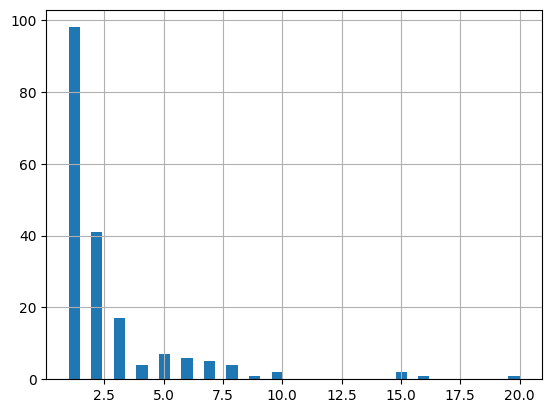

In [22]:
queries_proc['query_class'].value_counts().hist(bins=40)

### Labels

In [24]:
labels_proc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231873 entries, 0 to 231872
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id          231873 non-null  int64 
 1   query_id    231873 non-null  int64 
 2   product_id  231873 non-null  int64 
 3   label       231873 non-null  object
dtypes: int64(3), object(1)
memory usage: 7.1+ MB


In [20]:
labels_proc['label'].value_counts()

label
Partial       145676
Irrelevant     60720
Exact          25477
Name: count, dtype: int64

In [26]:
pd.merge(
    labels_proc['query_id'],
    queries_proc['query_id'],
    how='outer',
    indicator=True
)._merge.value_counts()

_merge
both          231873
left_only          0
right_only         0
Name: count, dtype: int64